# 05 — Tầng 7: Monte Carlo Cash-In Simulation

**Vị trí trong pipeline** (`../docs/reports/agent1_implementation_review.md` Tầng 7):
```
03_lightgbm_payment_quantiles → 04_conformal_calibration → [05_monte_carlo_cash_in] → 06_stress_testing_regime_detection → 07_backtesting_evaluation
```

**Vì sao tầng này là thành phần chịu lực, không phải "nice to have":**

Đánh giá pipeline đã chỉ ra (P0-2): nếu lấy **một điểm** `Q50` rồi bỏ tiền vào bucket tuần,
LightGBM thua baseline B1 trên cash wMAPE. Lý do không phải model kém — Q50 tối thiểu hoá
absolute error nên bị co về giữa. Cách sửa đúng là **đừng dùng một điểm**: biến mỗi hoá đơn
thành một phân phối ngày trả rồi cộng phân phối lại thành dải dòng tiền.

**Nhiệm vụ:**
1. Biến `[P10, P50, P90]` đã calibrate (notebook 04) thành phân phối ngày trả từng hoá đơn.
2. Mô phỏng 10.000 kịch bản → dải cash-in P10/P50/P90 theo ngày/tuần cho 30/60/90 ngày.
3. Xác định ngày đầu tiên dải P10 tụt dưới ngưỡng kế hoạch.
4. Xếp hạng hoá đơn/khách hàng đóng góp nhiều nhất vào rủi ro thiếu hụt.
5. **Backtest trên cutoff thật** để notebook 07 có cash metric theo tuần — thứ gate Tầng 9 đang thiếu.

> **Kết quả đáng chú ý nhất của notebook này không phải con số forecast, mà là §4b:**
> mô phỏng với giả định các hoá đơn độc lập cho ra dải cash-in **hẹp đến mức vô nghĩa**
> (chỉ 45% số tuần có tiền thực rơi vào dải 80%). Notebook đo, chẩn đoán và sửa lỗi đó
> bằng cấu trúc phụ thuộc được hiệu chỉnh trên validation.

## 📋 Decision Log (D24 → D32)

---

### D24 · Sampler A — nội suy hàm quantile (piecewise-linear + đuôi mũ)

Ta có đúng 3 điểm của hàm quantile. Sinh mẫu bằng inverse transform: bốc `u ~ U(0,1)` rồi nội suy.

| Vùng `u` | Công thức | Lý do |
|---|---|---|
| `[0,10; 0,50]`, `[0,50; 0,90]` | tuyến tính giữa 2 quantile | không bịa thêm giả định ngoài 3 điểm đã có |
| `u < 0,10` | tuyến tính tới `max(1, q₁₀ − (q₅₀ − q₁₀))` | đuôi trái bị chặn: không ai trả trước ngày T |
| `u > 0,90` | **mũ**: `q₉₀ + s·(−ln((1−u)/0,1))`, `s=(q₉₀−q₅₀)/2` | đuôi phải phải nặng |

Cắt cụt đuôi phải là sai lầm đắt nhất với bài toán thanh khoản: nó khiến hệ thống báo
"tiền sẽ về" cho đúng những hoá đơn sẽ trễ rất lâu.

So với triangular distribution mà plan gợi ý: triangular chỉ khớp min/mode/max nên **tái tạo
sai** 3 quantile đã có; nội suy quantile khớp đúng theo định nghĩa. Ta đổi so với plan và ghi rõ lý do.

---

### D25 · Sampler B — bootstrap residual theo nhóm

`ngày trả = q̂₅₀ + r`, `r` bốc từ pool residual `y − q̂₅₀` của calibration set **cùng nhóm aging**.
Giữ nguyên hình dạng thật của sai số (đa đỉnh, lệch), không giả định gì về đuôi. Nhược điểm:
nhóm mỏng cho pool nghèo, và mọi hoá đơn trong nhóm dùng chung một hình dạng.

---

### D26 · Chọn sampler bằng validation, không bằng test

Cùng kỷ luật như D20: backtest cả 2 sampler trên 9 cutoff validation, chọn theo wMAPE cash
tuần và band coverage. Sampler thắng mới được chạy trên test (báo cáo) và pool đang mở (triển khai).

---

### D27 · Điểm dự báo của một phân phối là kỳ vọng, không phải trung vị

Tổng tiền là đại lượng cộng tính: `E[Σ] = ΣE[·]` luôn đúng, còn `median(Σ) ≠ Σmedian(·)`.
Khi so wMAPE, MC dùng **mean**; trung vị được báo cáo song song nhưng không dùng để so.

---

### D31 · Cấu trúc phụ thuộc bằng Gaussian copula — sửa lỗi dải quá hẹp

Mô phỏng độc lập cho ra dải tổng **hẹp một cách phi lý**: cộng ~1.700 hoá đơn độc lập thì
định lý giới hạn trung tâm bóp phương sai của tổng lại, dải `[P10,P90]` co về gần bằng mean.
Đo được ở §4b: chỉ **45%** số tuần có tiền thực nằm trong dải 80%.

Sửa bằng copula Gaussian 3 tầng — vẫn giữ **nguyên** phân phối biên của từng hoá đơn
(marginal không đổi, chỉ đổi cách chúng liên kết):

```
z_i = √(1−ρ_c−ρ_m)·ε_i  +  √ρ_c·η_{cust(i)}  +  √ρ_m·ξ
u_i = Φ(z_i)                         → đưa vào sampler A hoặc B
```

- `ξ` : cú sốc chung toàn danh mục (điều kiện thị trường, chu kỳ cuối tháng).
- `η_c`: cú sốc mức khách hàng (một khách gặp khó thì **mọi** hoá đơn của họ cùng trễ).
- `ε_i`: phần riêng của từng hoá đơn.

`ρ_c`, `ρ_m` **không** được chọn theo cảm tính: quét lưới và chọn điểm cho band coverage
gần 80% nhất **trên validation**. Đây là bước hiệu chỉnh dải tổng, song song với việc CQR
hiệu chỉnh dải từng hoá đơn ở Tầng 6.

Lưu ý phạm vi: đây **không** phải "macro shock stochastic" mà plan Tầng 8 loại khỏi MVP.
Plan loại việc *bịa* một cú sốc vĩ mô ngoại sinh; ở đây ta chỉ thừa nhận rằng các hoá đơn
trong cùng một sổ AR **không độc lập**, và đo mức phụ thuộc đó từ chính dữ liệu.

---

### D32 · So sánh công bằng: phân phối phải đấu với phân phối (CRPS)

So wMAPE giữa `MC mean` và `B1 point` là so hai thứ khác loại — và metric wMAPE **thưởng cho
sự tập trung**: dự báo dồn hết tiền vào một tuần có thể thắng dự báo trải đều, kể cả khi nó
sai về bản chất rủi ro. Vì vậy ta thêm **CRPS** (Continuous Ranked Probability Score) và cho
baseline một phiên bản phân phối tương ứng:

```
B1-dist = B1 point + bootstrap residual (y − B1) theo nhóm, cùng copula, cùng số mô phỏng
```

CRPS quy về cùng đơn vị tiền và chuẩn hoá theo tổng cash thực để đọc như wMAPE.
Cả hai metric đều được báo cáo; notebook 07 dùng cả hai cho gate.

---

### D29 · Số mô phỏng: 10.000 cho forecast, 2.000 cho backtest

Sai số MC của một phân vị co theo `1/√B`. §4e đo trực tiếp nhiễu ở B=2.000 để chứng minh
nó nhỏ hơn nhiều so với chênh lệch giữa các phương án đang so.

---

### D30 · Ngưỡng kế hoạch là giả định, không phải dữ liệu

Dataset không chứa kế hoạch chi. Proxy = **trung vị dòng tiền thu thực tế theo tuần trong 13
tuần cuối** trước ngày dự báo. Mọi phát biểu "ngày đầu tiên thiếu hụt" phải ghi kèm chú thích
này — CFO phải thay bằng số kế hoạch thật.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.special import erf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 210)
pd.set_option("display.float_format", "{:,.3f}".format)

BASE = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "reference_notebooks").is_dir() and (parent / ".gitignore").is_file()
)
PROC = BASE / "data" / "processed"

IN_LIVE = PROC / "cqr_current_forecast.csv"
IN_SNAP = PROC / "cqr_snapshot_predictions.csv"
IN_RESID = PROC / "cqr_residuals_calibration.csv"
IN_CLEAN = PROC / "invoices_ar_clean.csv"

OUT_DAILY = PROC / "mc_daily_cash_forecast.csv"
OUT_WEEKLY = PROC / "mc_weekly_cash_forecast.csv"
OUT_HORIZON = PROC / "mc_horizon_summary.csv"
OUT_INVOICE = PROC / "mc_invoice_risk.csv"
OUT_CUSTOMER = PROC / "mc_customer_risk.csv"
OUT_BACKTEST = PROC / "mc_backtest_weekly.csv"
OUT_SAMPLER = PROC / "mc_sampler_selection.csv"
OUT_RHO = PROC / "mc_dependence_grid.csv"
OUT_SHORTFALL = PROC / "mc_shortfall_report.csv"

HORIZON_DAYS = 91           # 13 tuần chẵn
WEEKS = HORIZON_DAYS // 7
HORIZONS = [30, 60, 90]
N_SIMS_FORECAST = 10_000    # D29
N_SIMS_BACKTEST = 2_000     # D29
SIM_BATCH = 250
DAY_FLOOR = 1.0
SEED = 42
PLAN_LOOKBACK_WEEKS = 13    # D30

C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
C_GOOD, C_WARN, C_SERIOUS, C_CRIT = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
C_INK, C_INK2, C_GRID = "#0b0b0b", "#52514e", "#d8d7d2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "xtick.color": C_INK2, "ytick.color": C_INK2, "text.color": C_INK,
    "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

print(f"Horizon: {HORIZON_DAYS} ngày = {WEEKS} tuần")
print(f"Sims   : forecast {N_SIMS_FORECAST:,} | backtest {N_SIMS_BACKTEST:,}")

Horizon: 91 ngày = 13 tuần
Sims   : forecast 10,000 | backtest 2,000


## 1. Load input đã calibrate

In [2]:
live = pd.read_csv(IN_LIVE, parse_dates=["cutoff_date", "issue_date", "due_date"])
snap = pd.read_csv(IN_SNAP, parse_dates=["cutoff_date", "due_date", "target_paid_date"])
resid = pd.read_csv(IN_RESID)
clean = pd.read_csv(IN_CLEAN, parse_dates=["issue_date", "due_date", "paid_date"])

LIVE_CUTOFF = live["cutoff_date"].iloc[0]
print(f"Pool đang mở : {len(live):,} hoá đơn | ${live['amount'].sum():,.0f} | cutoff {LIVE_CUTOFF.date()}")
print(f"Snapshot     : {len(snap):,} dòng, {snap['cutoff_date'].nunique()} cutoff")
print(f"Residual pool: {len(resid):,} dòng")
print()
print("Quantile đã calibrate của pool đang mở (ngày):")
print(live[["cal_q10", "cal_q50", "cal_q90"]].describe(percentiles=[0.1, 0.5, 0.9]).to_string())

# ── D30: ngưỡng kế hoạch proxy ─────────────────────────────────────────────
paid_hist = clean.loc[clean["paid_date"].notna(), ["paid_date", "amount"]].copy()
window_start = LIVE_CUTOFF - pd.Timedelta(weeks=PLAN_LOOKBACK_WEEKS)
recent = paid_hist[(paid_hist["paid_date"] > window_start) & (paid_hist["paid_date"] <= LIVE_CUTOFF)]
weekly_hist = recent.set_index("paid_date")["amount"].resample("W-FRI").sum()
PLAN_WEEKLY = float(weekly_hist.median())
PLAN_DAILY = PLAN_WEEKLY / 7.0
print()
print(f"Ngưỡng kế hoạch proxy (D30) = ${PLAN_WEEKLY:,.0f}/tuần (${PLAN_DAILY:,.0f}/ngày)")
print(f"  = trung vị thu thực tế {len(weekly_hist)} tuần, {window_start.date()} → {LIVE_CUTOFF.date()}")

Pool đang mở : 9,681 hoá đơn | $312,538,769 | cutoff 2020-05-22
Snapshot     : 76,151 dòng, 47 cutoff
Residual pool: 15,162 dòng

Quantile đã calibrate của pool đang mở (ngày):
        cal_q10   cal_q50   cal_q90
count 9,681.000 9,681.000 9,681.000
mean      5.086    16.347    35.279
std       1.732     5.479    13.212
min       1.000     2.714     3.831
10%       3.164     8.346    20.351
50%       5.268    17.057    34.065
90%       6.161    22.909    53.936
max      33.395    48.319   106.136

Ngưỡng kế hoạch proxy (D30) = $729,069/tuần ($104,153/ngày)
  = trung vị thu thực tế 13 tuần, 2020-02-21 → 2020-05-22


## 2. Copula phụ thuộc + hai sampler (D24, D25, D31)

Tất cả sampler nhận **cùng** ma trận `u` sinh từ copula, nên khi so sánh chúng ta chỉ đổi
phân phối biên chứ không đổi cấu trúc phụ thuộc.

In [3]:
def norm_cdf(z):
    """Φ(z) — dùng erf để không phải gọi scipy.stats trên mảng lớn."""
    return 0.5 * (1.0 + erf(z / np.sqrt(2.0, dtype=np.float32)))


def make_uniforms(n_inv, cust_codes, n_cust, rho_c, rho_m, batch, rng):
    """Sinh u (n_inv × batch) với tương quan mức khách hàng và toàn danh mục (D31)."""
    w_i = np.sqrt(max(1.0 - rho_c - rho_m, 0.0), dtype=np.float32)
    z = (w_i * rng.standard_normal((n_inv, batch), dtype=np.float32))
    if rho_c > 0:
        eta = rng.standard_normal((n_cust, batch), dtype=np.float32)
        z += np.float32(np.sqrt(rho_c)) * eta[cust_codes]
    if rho_m > 0:
        xi = rng.standard_normal((1, batch), dtype=np.float32)
        z += np.float32(np.sqrt(rho_m)) * xi
    return np.clip(norm_cdf(z), 1e-6, 1 - 1e-6)


def pwl_from_u(u, q10, q50, q90, floor=DAY_FLOOR):
    """Sampler A: nội suy hàm quantile (D24)."""
    q10, q50, q90 = q10[:, None], q50[:, None], q90[:, None]
    left = np.maximum(floor, q10 - (q50 - q10))
    scale = np.maximum((q90 - q50) / 2.0, 0.5)
    x = np.where(
        u < 0.10, left + (u / 0.10) * (q10 - left),
        np.where(
            u < 0.50, q10 + ((u - 0.10) / 0.40) * (q50 - q10),
            np.where(
                u < 0.90, q50 + ((u - 0.50) / 0.40) * (q90 - q50),
                q90 + scale * (-np.log(np.maximum((1.0 - u) / 0.10, 1e-7))),
            ),
        ),
    )
    return np.maximum(x, floor)


def bootstrap_from_u(u, center, groups, pools, floor=DAY_FLOOR, min_pool=100):
    """Sampler B: center + residual lấy theo phân vị u của pool residual nhóm (D25)."""
    out = np.empty_like(u)
    for g in np.unique(groups):
        m = groups == g
        pool = pools.get(g, pools["__global__"])
        if len(pool) < min_pool:
            pool = pools["__global__"]
        idx = np.clip((u[m] * len(pool)).astype(np.int32), 0, len(pool) - 1)
        out[m] = center[m, None] + pool[idx]
    return np.maximum(out, floor)


def build_pools(frame, resid_col):
    pools = {g: np.sort(p[resid_col].to_numpy(np.float32))
             for g, p in frame.groupby("cal_group")}
    pools["__global__"] = np.sort(frame[resid_col].to_numpy(np.float32))
    return pools


RESID_POOLS = build_pools(resid, "residual_days")
print("Pool residual của LightGBM (y − P50) theo nhóm:")
for g, arr in RESID_POOLS.items():
    print(f"  {g:<16s} n={len(arr):>6,}  p10={np.percentile(arr,10):>7.1f}  "
          f"p50={np.percentile(arr,50):>6.1f}  p90={np.percentile(arr,90):>6.1f}")

Pool residual của LightGBM (y − P50) theo nhóm:
  1_30             n= 1,306  p10=  -11.5  p50=  -1.3  p90=   8.7
  31_60            n=   339  p10=   -9.3  p50=  -3.9  p90=   6.2
  not_due          n=13,438  p10=   -2.5  p50=  -0.0  p90=   4.0
  overdue_61_plus  n=    79  p10=  -15.1  p50=  -3.1  p90=   8.5
  __global__       n=15,162  p10=   -3.9  p50=  -0.1  p90=   4.5


### 2b. Kiểm tra sampler tái tạo đúng quantile đầu vào

Nếu bước này sai thì mọi con số phía sau đều sai, nên phải kiểm trước khi chạy bất cứ thứ gì.

In [4]:
rng_chk = np.random.default_rng(SEED)
chk = live.sample(400, random_state=SEED)
u_chk = make_uniforms(len(chk), np.zeros(len(chk), int), 1, 0.0, 0.0, 20_000, rng_chk)
draw_chk = pwl_from_u(u_chk, chk["cal_q10"].to_numpy(np.float32),
                      chk["cal_q50"].to_numpy(np.float32), chk["cal_q90"].to_numpy(np.float32))
emp = np.percentile(draw_chk, [10, 50, 90], axis=1)
print("Sampler A, B=20.000 — sai lệch giữa quantile mô phỏng và quantile đầu vào (ngày):")
for i, (name, col) in enumerate([("P10", "cal_q10"), ("P50", "cal_q50"), ("P90", "cal_q90")]):
    diff = emp[i] - chk[col].to_numpy(float)
    print(f"  {name}: trung bình {diff.mean():+.4f}, tuyệt đối trung bình {np.abs(diff).mean():.4f}, "
          f"tối đa {np.abs(diff).max():.3f}")
print("→ sai lệch chỉ ở mức nhiễu lấy mẫu (~1/√B). Inverse transform đúng.")

Sampler A, B=20.000 — sai lệch giữa quantile mô phỏng và quantile đầu vào (ngày):
  P10: trung bình -0.0101, tuyệt đối trung bình 0.0592, tối đa 0.311
  P50: trung bình +0.0349, tuyệt đối trung bình 0.1021, tối đa 0.798
  P90: trung bình +0.0411, tuyệt đối trung bình 0.1182, tối đa 0.810
→ sai lệch chỉ ở mức nhiễu lấy mẫu (~1/√B). Inverse transform đúng.


## 3. Bộ máy mô phỏng và tổng hợp

Tiền cộng theo **ngày**, chạy theo lô kịch bản để không giữ ma trận `(hoá đơn × 10.000)` trong RAM.
Hoá đơn rơi quá `HORIZON_DAYS` vào ô riêng `beyond` — **không** dồn vào ngày cuối, vì dồn như
vậy tạo một đỉnh tiền giả ở cuối kỳ.

In [5]:
def simulate_cash(amounts, day_fn, n_sims, rng, horizon=HORIZON_DAYS, batch=SIM_BATCH):
    """day_fn(batch, rng) -> ma trận ngày (n_inv × batch).

    Trả daily (horizon × n_sims), beyond (n_sims), paid_prob {h: n_inv}, expected_days (n_inv).
    """
    n_inv = len(amounts)
    amounts = np.asarray(amounts, dtype=np.float64)
    daily = np.zeros((horizon, n_sims), dtype=np.float64)
    beyond = np.zeros(n_sims, dtype=np.float64)
    paid_counts = {h: np.zeros(n_inv) for h in HORIZONS}
    day_sum = np.zeros(n_inv)

    done = 0
    while done < n_sims:
        b = min(batch, n_sims - done)
        days = day_fn(b, rng)
        day_idx = np.ceil(days).astype(np.int32)
        day_sum += days.sum(axis=1)
        for h in HORIZONS:
            paid_counts[h] += (day_idx <= h).sum(axis=1)

        inside = day_idx <= horizon
        sim_idx = np.broadcast_to(np.arange(b, dtype=np.int32), day_idx.shape)
        w = np.broadcast_to(amounts[:, None], day_idx.shape)

        flat = ((day_idx - 1) * b + sim_idx)[inside].ravel()
        acc = np.bincount(flat, weights=w[inside].ravel(), minlength=horizon * b)
        daily[:, done:done + b] = acc.reshape(horizon, b)

        if (~inside).any():
            beyond[done:done + b] = np.bincount(
                sim_idx[~inside].ravel(), weights=w[~inside].ravel(), minlength=b)
        done += b

    return daily, beyond, {h: paid_counts[h] / n_sims for h in HORIZONS}, day_sum / n_sims


def weekly_from_daily(daily, weeks=WEEKS):
    return daily[: weeks * 7].reshape(weeks, 7, -1).sum(axis=1)


def band(matrix, qs=(5, 10, 50, 90, 95)):
    out = {f"p{q:02d}": np.percentile(matrix, q, axis=-1) for q in qs}
    out["mean"] = matrix.mean(axis=-1)
    return out


def crps_ensemble(sims, actual, rng):
    """CRPS xấp xỉ từ ensemble: E|X−y| − ½E|X−X'| (D32)."""
    a = np.abs(sims - actual).mean()
    perm = rng.permutation(sims)
    return float(a - 0.5 * np.abs(sims - perm).mean())


print("Engine sẵn sàng.")

Engine sẵn sàng.


## 4. Backtest trên cutoff thật

Với mỗi cutoff `T`: so **tiền thu thực tế theo tuần** (từ `target_paid_date`) với dải MC.
Đây chính là phần gate Tầng 9 rule 1 đang thiếu.

In [6]:
def make_day_fn(part, kind, rho_c, rho_m, pools, center_col, q_cols=None):
    """Đóng gói một cấu hình mô phỏng thành hàm day_fn dùng cho simulate_cash."""
    codes, uniq = pd.factorize(part["customer_id"])
    codes = codes.astype(np.int32)
    n_cust = len(uniq)
    groups = part["cal_group"].to_numpy()
    center = part[center_col].to_numpy(np.float32)
    if q_cols is not None:
        q10 = part[q_cols[0]].to_numpy(np.float32)
        q50 = part[q_cols[1]].to_numpy(np.float32)
        q90 = part[q_cols[2]].to_numpy(np.float32)

    def day_fn(b, rng):
        u = make_uniforms(len(part), codes, n_cust, rho_c, rho_m, b, rng)
        if kind == "pwl":
            return pwl_from_u(u, q10, q50, q90)
        return bootstrap_from_u(u, center, groups, pools)

    return day_fn


def backtest(frame, splits, kind, rho_c=0.0, rho_m=0.0, pools=None,
             center_col="cal_q50", q_cols=("cal_q10", "cal_q50", "cal_q90"),
             n_sims=N_SIMS_BACKTEST, seed=SEED, label="MC"):
    """Backtest theo tuần cho từng cutoff. Trả DataFrame cutoff × tuần."""
    pools = RESID_POOLS if pools is None else pools
    rows = []
    sub = frame[frame["time_split"].isin(splits)]
    for k, (cutoff, part) in enumerate(sub.groupby("cutoff_date")):
        rng = np.random.default_rng(seed + k)
        amounts = part["amount"].to_numpy(float)
        day_fn = make_day_fn(part, kind, rho_c, rho_m, pools, center_col, q_cols)
        daily, _, _, _ = simulate_cash(amounts, day_fn, n_sims, rng)
        wk = weekly_from_daily(daily)
        wb = band(wk)

        actual_week = np.floor((np.ceil(part["remaining_days_at_T"].to_numpy(float)) - 1) / 7).astype(int)
        b1_week = np.floor((np.ceil(np.maximum(part["pred_b1_remaining_days"].to_numpy(float), DAY_FLOOR)) - 1) / 7).astype(int)
        q50_week = np.floor((np.ceil(np.maximum(part["cal_q50"].to_numpy(float), DAY_FLOOR)) - 1) / 7).astype(int)

        for w in range(WEEKS):
            actual = float(amounts[actual_week == w].sum())
            rows.append({
                "label": label, "kind": kind, "rho_c": rho_c, "rho_m": rho_m,
                "time_split": part["time_split"].iloc[0], "cutoff_date": cutoff,
                "week_index": w + 1, "week_end": cutoff + pd.Timedelta(days=7 * (w + 1)),
                "actual_cash": actual,
                "mc_mean": float(wb["mean"][w]), "mc_p10": float(wb["p10"][w]),
                "mc_p50": float(wb["p50"][w]), "mc_p90": float(wb["p90"][w]),
                "crps": crps_ensemble(wk[w], actual, rng),
                "b1_point_cash": float(amounts[b1_week == w].sum()),
                "lgbm_q50_point_cash": float(amounts[q50_week == w].sum()),
                "pool_amount": float(amounts.sum()),
            })
    return pd.DataFrame(rows)


def cash_metrics(bt):
    """wMAPE tuần, bias, band coverage, CRPS chuẩn hoá."""
    denom = bt["actual_cash"].sum()
    out = []
    for label, col in [("MC mean", "mc_mean"), ("MC median", "mc_p50"),
                       ("B1 point", "b1_point_cash"), ("LGBM Q50 point", "lgbm_q50_point_cash")]:
        out.append({"forecast": label,
                    "weekly_wmape": (bt[col] - bt["actual_cash"]).abs().sum() / denom,
                    "bias_pct": (bt[col].sum() - denom) / denom})
    cov = float(((bt["actual_cash"] >= bt["mc_p10"]) & (bt["actual_cash"] <= bt["mc_p90"])).mean())
    crps_n = float(bt["crps"].sum() / denom)
    for row in out:
        row["mc_band_coverage"] = cov if row["forecast"].startswith("MC") else np.nan
        row["crps_norm"] = crps_n if row["forecast"].startswith("MC") else np.nan
    return pd.DataFrame(out)


sel_rows = []
for kind in ("pwl", "bootstrap"):
    bt_val = backtest(snap, ["validation"], kind)
    m = cash_metrics(bt_val)
    mc = m.iloc[0]
    sel_rows.append({"sampler": kind, "weekly_wmape": mc["weekly_wmape"],
                     "bias_pct": mc["bias_pct"], "band_coverage": mc["mc_band_coverage"],
                     "crps_norm": mc["crps_norm"]})
    print(f"[validation | sampler={kind} | độc lập ρ=0]")
    print(m.to_string(index=False))
    print()

sampler_selection = pd.DataFrame(sel_rows).sort_values("weekly_wmape")
BEST_SAMPLER = sampler_selection.iloc[0]["sampler"]
print("Chọn sampler trên validation (D26)")
print(sampler_selection.to_string(index=False))
print(f"→ sampler: **{BEST_SAMPLER}**")

[validation | sampler=pwl | độc lập ρ=0]
      forecast  weekly_wmape  bias_pct  mc_band_coverage  crps_norm
       MC mean         0.214    -0.001             0.419      0.186
     MC median         0.213    -0.003             0.419      0.186
      B1 point         0.094    -0.002               NaN        NaN
LGBM Q50 point         0.194     0.000               NaN        NaN



[validation | sampler=bootstrap | độc lập ρ=0]
      forecast  weekly_wmape  bias_pct  mc_band_coverage  crps_norm
       MC mean         0.198    -0.000             0.444      0.172
     MC median         0.197    -0.002             0.444      0.172
      B1 point         0.094    -0.002               NaN        NaN
LGBM Q50 point         0.194     0.000               NaN        NaN

Chọn sampler trên validation (D26)
  sampler  weekly_wmape  bias_pct  band_coverage  crps_norm
bootstrap         0.198    -0.000          0.444      0.172
      pwl         0.214    -0.001          0.419      0.186
→ sampler: **bootstrap**


### 4b. Chẩn đoán: vì sao dải tổng vô dụng khi giả định độc lập

Band coverage ~45% nghĩa là: dải "80%" của ta chỉ chứa tiền thực trong chưa tới **một nửa**
số tuần. Bảng dưới chỉ ra hai lỗi khác nhau, và chỉ một trong hai sửa được bằng cấu trúc
phụ thuộc.

In [7]:
diag = backtest(snap, ["validation"], BEST_SAMPLER)
diag["in_band"] = (diag["actual_cash"] >= diag["mc_p10"]) & (diag["actual_cash"] <= diag["mc_p90"])
diag["above_p90"] = diag["actual_cash"] > diag["mc_p90"]
diag["below_p10"] = diag["actual_cash"] < diag["mc_p10"]
by_week = (diag.groupby("week_index")
           .agg(coverage=("in_band", "mean"), above_p90=("above_p90", "mean"),
                below_p10=("below_p10", "mean"), actual=("actual_cash", "mean"),
                mc_mean=("mc_mean", "mean"), p10=("mc_p10", "mean"), p90=("mc_p90", "mean"))
           .reset_index())
by_week["rel_width"] = (by_week["p90"] - by_week["p10"]) / by_week["actual"].replace(0, np.nan)
print("Validation — coverage dải theo tuần (ρ = 0, độc lập)")
print(by_week.to_string(index=False))
print()
print("Đọc bảng:")
print("  • Tuần 1: 100% số cutoff có tiền thực NẰM TRÊN P90 — model trả tiền về chậm hơn thực tế")
print("    một cách hệ thống. Đây là **sai lệch mức model**, cấu trúc phụ thuộc không sửa được.")
print("  • Tuần 3→9: tiền thực nằm DƯỚI P10 — model kéo dài đuôi quá mức so với thực tế.")
print("  • Cột rel_width: dải rộng chỉ vài phần trăm so với chính lượng tiền tuần đó — đây là")
print("    hệ quả của giả định độc lập (D31), và đây là phần sửa được.")

Validation — coverage dải theo tuần (ρ = 0, độc lập)
 week_index  coverage  above_p90  below_p10         actual        mc_mean            p10            p90  rel_width
          1     0.000      1.000      0.000 23,069,463.469 18,853,092.570 18,035,496.257 19,660,534.876      0.070
          2     0.333      0.222      0.444 20,718,046.688 21,023,291.988 20,045,207.850 22,017,185.554      0.095
          3     0.222      0.000      0.778  6,204,890.713  8,775,038.371  8,035,323.711  9,531,941.497      0.241
          4     0.000      0.222      0.778  1,907,167.743  2,585,873.905  2,170,136.092  3,019,381.605      0.445
          5     0.111      0.222      0.667  1,321,678.050  1,482,013.453  1,205,587.982  1,770,695.053      0.428
          6     0.222      0.111      0.667    699,649.164    794,160.763    594,058.839  1,008,583.331      0.592
          7     0.222      0.000      0.778    228,253.603    392,934.102    258,363.635    546,728.009      1.263
          8     0.444      

### 4c. Hiệu chỉnh cấu trúc phụ thuộc trên validation (D31)

Quét lưới `(ρ_c, ρ_m)`, chọn điểm cho band coverage gần 80% nhất. **Test không tham gia.**

In [8]:
RHO_GRID = [(0.0, 0.0), (0.25, 0.0), (0.50, 0.0), (1.00, 0.0),
            (0.0, 0.25), (0.0, 0.50), (0.0, 0.75), (0.0, 1.00),
            (0.25, 0.25), (0.25, 0.50), (0.50, 0.25), (0.50, 0.50),
            (0.25, 0.75), (0.75, 0.25)]

grid_rows = []
for rc, rm in RHO_GRID:
    bt = backtest(snap, ["validation"], BEST_SAMPLER, rho_c=rc, rho_m=rm)
    m = cash_metrics(bt).iloc[0]
    rel_w = float(((bt["mc_p90"] - bt["mc_p10"]).sum()) / bt["actual_cash"].sum())
    grid_rows.append({"rho_cust": rc, "rho_market": rm,
                      "band_coverage": m["mc_band_coverage"],
                      "weekly_wmape": m["weekly_wmape"],
                      "crps_norm": m["crps_norm"], "rel_band_width": rel_w})

rho_grid = pd.DataFrame(grid_rows)
rho_grid["cov_dev"] = (rho_grid["band_coverage"] - 0.80).abs()
rho_grid = rho_grid.sort_values(["cov_dev", "rel_band_width"])
print("Lưới cấu trúc phụ thuộc (validation)")
print(rho_grid.to_string(index=False))

RHO_C = float(rho_grid.iloc[0]["rho_cust"])
RHO_M = float(rho_grid.iloc[0]["rho_market"])
best_cov = float(rho_grid.iloc[0]["band_coverage"])
print()
print(f"→ Chọn ρ_khách_hàng = {RHO_C:.2f}, ρ_danh_mục = {RHO_M:.2f}  (band coverage {best_cov:.1%})")
if best_cov < 0.75:
    print("  ⚠ Ngay cả cấu hình tốt nhất vẫn dưới 75%. Phần thiếu không đến từ tương quan mà từ")
    print("    sai lệch timing mức model đã thấy ở §4b — phải ghi vào hạn chế, không được giấu.")

Lưới cấu trúc phụ thuộc (validation)
 rho_cust  rho_market  band_coverage  weekly_wmape  crps_norm  rel_band_width  cov_dev
    0.250       0.750          0.803         0.199      0.124           0.839    0.003
    0.000       0.750          0.795         0.193      0.122           0.830    0.005
    0.000       1.000          0.812         0.193      0.121           1.003    0.012
    0.500       0.500          0.769         0.199      0.124           0.704    0.031
    0.250       0.500          0.752         0.199      0.125           0.690    0.048
    0.000       0.500          0.735         0.194      0.122           0.682    0.065
    0.750       0.250          0.709         0.199      0.126           0.546    0.091
    0.500       0.250          0.675         0.199      0.128           0.517    0.125
    0.250       0.250          0.650         0.199      0.129           0.503    0.150
    0.000       0.250          0.641         0.195      0.127           0.493    0.159
    1.

### 4d. Backtest test set — con số dùng cho gate Tầng 9

Bao gồm cả **baseline dạng phân phối** (`B1 + bootstrap residual của B1`) để CRPS được so
công bằng phân phối với phân phối (D32).

In [9]:
# ── Pool residual của baseline B1, tính trên đúng calibration set ─────────
val_rows = snap[snap["time_split"] == "validation"].copy()
val_rows["resid_b1"] = (val_rows["remaining_days_at_T"]
                        - np.maximum(val_rows["pred_b1_remaining_days"], DAY_FLOOR))
B1_POOLS = build_pools(val_rows, "resid_b1")
snap_b1 = snap.copy()
snap_b1["b1_center"] = np.maximum(snap_b1["pred_b1_remaining_days"], DAY_FLOOR)

bt_test_mc = backtest(snap, ["test"], BEST_SAMPLER, rho_c=RHO_C, rho_m=RHO_M, label="MC_lgbm")
bt_test_b1 = backtest(snap_b1, ["test"], "bootstrap", rho_c=RHO_C, rho_m=RHO_M,
                      pools=B1_POOLS, center_col="b1_center", label="MC_b1")

m_mc = cash_metrics(bt_test_mc)
m_b1 = cash_metrics(bt_test_b1)

print(f"TEST — {bt_test_mc['cutoff_date'].nunique()} cutoff × {WEEKS} tuần")
print()
print("[A] Phân phối từ LightGBM + CQR (Tầng 5→6→7)")
print(m_mc.to_string(index=False))
print()
print("[B] Phân phối từ baseline B1 + bootstrap residual (cùng copula, cùng B)")
print(m_b1.to_string(index=False))
print()

mc_w = m_mc.loc[0, "weekly_wmape"]; mc_crps = m_mc.loc[0, "crps_norm"]; mc_cov = m_mc.loc[0, "mc_band_coverage"]
b1d_w = m_b1.loc[0, "weekly_wmape"]; b1d_crps = m_b1.loc[0, "crps_norm"]; b1d_cov = m_b1.loc[0, "mc_band_coverage"]
b1p_w = m_mc.loc[2, "weekly_wmape"]; q50p_w = m_mc.loc[3, "weekly_wmape"]

summary_cash = pd.DataFrame([
    {"forecast": "B1 point (điểm)", "weekly_wmape": b1p_w, "crps_norm": np.nan, "band_coverage": np.nan},
    {"forecast": "LGBM Q50 point (điểm)", "weekly_wmape": q50p_w, "crps_norm": np.nan, "band_coverage": np.nan},
    {"forecast": "B1 + bootstrap (phân phối)", "weekly_wmape": b1d_w, "crps_norm": b1d_crps, "band_coverage": b1d_cov},
    {"forecast": "LGBM + CQR + MC (phân phối)", "weekly_wmape": mc_w, "crps_norm": mc_crps, "band_coverage": mc_cov},
])
print("BẢNG SO SÁNH CASH THEO TUẦN (test set) — thấp hơn là tốt hơn")
print(summary_cash.to_string(index=False))
print()
print(f"CRPS: LightGBM {mc_crps:.4f} vs baseline {b1d_crps:.4f} → "
      f"{(b1d_crps - mc_crps)/b1d_crps:+.1%} "
      f"{'✅ model thắng baseline trên metric phân phối' if mc_crps < b1d_crps else '❌ model thua'}")
print(f"wMAPE điểm: MC {mc_w:.2%} vs B1 điểm {b1p_w:.2%} → "
      f"{'✅' if mc_w < b1p_w else '❌ baseline điểm vẫn thắng'}")
print()
print("Vì sao hai metric có thể cho hai kết luận khác nhau (D32): wMAPE thưởng cho dự báo")
print("tập trung — dồn hết tiền vào một tuần đôi khi trúng bucket tốt hơn là trải theo xác suất.")
print("CRPS chấm toàn bộ phân phối, nên nó là metric đúng loại cho một hệ thống cảnh báo rủi ro.")
print("Notebook 07 báo cáo cả hai và không được chọn metric sau khi đã biết kết quả.")

TEST — 10 cutoff × 13 tuần

[A] Phân phối từ LightGBM + CQR (Tầng 5→6→7)
      forecast  weekly_wmape  bias_pct  mc_band_coverage  crps_norm
       MC mean         0.232     0.003             0.538      0.143
     MC median         0.183    -0.007             0.538      0.143
      B1 point         0.105    -0.001               NaN        NaN
LGBM Q50 point         0.180     0.003               NaN        NaN

[B] Phân phối từ baseline B1 + bootstrap residual (cùng copula, cùng B)
      forecast  weekly_wmape  bias_pct  mc_band_coverage  crps_norm
       MC mean         0.200    -0.001             0.623      0.129
     MC median         0.156    -0.012             0.623      0.129
      B1 point         0.105    -0.001               NaN        NaN
LGBM Q50 point         0.180     0.003               NaN        NaN

BẢNG SO SÁNH CASH THEO TUẦN (test set) — thấp hơn là tốt hơn
                   forecast  weekly_wmape  crps_norm  band_coverage
            B1 point (điểm)         0.105   

In [10]:
# ── D29: nhiễu Monte Carlo ở B = 2.000 ────────────────────────────────────
last_cut = snap.loc[snap["time_split"] == "test", "cutoff_date"].max()
probe = snap[(snap["time_split"] == "test") & (snap["cutoff_date"] == last_cut)]
reps = []
for r in range(5):
    rng = np.random.default_rng(1000 + r)
    fn = make_day_fn(probe, BEST_SAMPLER, RHO_C, RHO_M, RESID_POOLS, "cal_q50",
                     ("cal_q10", "cal_q50", "cal_q90"))
    d, _, _, _ = simulate_cash(probe["amount"].to_numpy(float), fn, N_SIMS_BACKTEST, rng)
    reps.append(weekly_from_daily(d).mean(axis=1))
reps = np.vstack(reps)
rel_sd = reps.std(axis=0, ddof=1) / reps.mean(axis=0)
print(f"Nhiễu MC ở B={N_SIMS_BACKTEST:,} (5 lần chạy lại, cutoff {pd.Timestamp(last_cut).date()}):")
print(f"  độ lệch chuẩn tương đối của cash tuần: trung bình {rel_sd.mean():.3%}, tối đa {rel_sd.max():.3%}")
print(f"  chênh lệch wMAPE đang so giữa các phương án: {abs(b1p_w - mc_w):.2%}")
print()
print("Nhiễu này cao hơn hẳn so với khi ρ=0, và đó là hệ quả trực tiếp của cú sốc chung: khi")
print("cả danh mục dịch chuyển cùng nhau thì trung bình mẫu hội tụ chậm hơn nhiều. Hai biện pháp:")
print("  1. So sánh THEO CẶP: mọi phương án dùng cùng seed cho cùng cutoff (seed = SEED + k),")
print("     nên cùng chuỗi cú sốc chung → phần nhiễu này triệt tiêu khi lấy hiệu.")
print("  2. Forecast chính thức chạy 10.000 lần lặp, nhiễu giảm còn ~1/√5 mức trên.")

Nhiễu MC ở B=2,000 (5 lần chạy lại, cutoff 2020-02-21):
  độ lệch chuẩn tương đối của cash tuần: trung bình 2.315%, tối đa 11.818%
  chênh lệch wMAPE đang so giữa các phương án: 12.75%

Nhiễu này cao hơn hẳn so với khi ρ=0, và đó là hệ quả trực tiếp của cú sốc chung: khi
cả danh mục dịch chuyển cùng nhau thì trung bình mẫu hội tụ chậm hơn nhiều. Hai biện pháp:
  1. So sánh THEO CẶP: mọi phương án dùng cùng seed cho cùng cutoff (seed = SEED + k),
     nên cùng chuỗi cú sốc chung → phần nhiễu này triệt tiêu khi lấy hiệu.
  2. Forecast chính thức chạy 10.000 lần lặp, nhiễu giảm còn ~1/√5 mức trên.


## 5. Forecast chính thức trên 9.681 hoá đơn đang mở

In [11]:
rng = np.random.default_rng(SEED)
amounts_live = live["amount"].to_numpy(float)
live_fn = make_day_fn(live, BEST_SAMPLER, RHO_C, RHO_M, RESID_POOLS, "cal_q50",
                      ("cal_q10", "cal_q50", "cal_q90"))
daily_live, beyond_live, paid_prob, exp_days = simulate_cash(
    amounts_live, live_fn, N_SIMS_FORECAST, rng)

weekly_live = weekly_from_daily(daily_live)
cum_daily = np.cumsum(daily_live, axis=0)
daily_band, weekly_band, cum_band = band(daily_live), band(weekly_live), band(cum_daily)

print(f"Đã mô phỏng {N_SIMS_FORECAST:,} kịch bản × {len(live):,} hoá đơn "
      f"(${amounts_live.sum():,.0f}) với ρ_c={RHO_C}, ρ_m={RHO_M}.")
print(f"Tiền rơi ngoài {HORIZON_DAYS} ngày: mean ${beyond_live.mean():,.0f} "
      f"({beyond_live.mean()/amounts_live.sum():.2%} dư nợ)")

Đã mô phỏng 10,000 kịch bản × 9,681 hoá đơn ($312,538,769) với ρ_c=0.25, ρ_m=0.75.
Tiền rơi ngoài 91 ngày: mean $85 (0.00% dư nợ)


### 5b. Dải cash-in theo horizon 30 / 60 / 90 ngày

In [12]:
hz_rows = []
for h in HORIZONS:
    cum_h = cum_daily[h - 1]
    hz_rows.append({
        "horizon_days": h,
        "p10": np.percentile(cum_h, 10), "p50": np.percentile(cum_h, 50),
        "p90": np.percentile(cum_h, 90), "mean": cum_h.mean(),
        "share_open_p10": np.percentile(cum_h, 10) / amounts_live.sum(),
        "share_open_mean": cum_h.mean() / amounts_live.sum(),
        "plan_need": PLAN_DAILY * h,
        "prob_below_plan": float((cum_h < PLAN_DAILY * h).mean()),
    })
horizon_summary = pd.DataFrame(hz_rows)
print("Dòng tiền thu tích luỹ từ AR đang mở (USD)")
print(horizon_summary.to_string(index=False))
print()
print(f"Đọc dòng h=30: với xác suất 90%, thu được ít nhất ${horizon_summary.loc[0,'p10']:,.0f} "
      f"trong 30 ngày tới từ sổ AR hiện tại.")

Dòng tiền thu tích luỹ từ AR đang mở (USD)
 horizon_days             p10             p50             p90            mean  share_open_p10  share_open_mean     plan_need  prob_below_plan
           30 274,393,765.157 312,040,256.515 312,283,007.200 298,169,109.059           0.878            0.954 3,124,583.529            0.000
           60 312,528,564.898 312,538,768.520 312,538,768.520 312,371,232.578           1.000            0.999 6,249,167.057            0.000
           90 312,538,768.520 312,538,768.520 312,538,768.520 312,538,675.041           1.000            1.000 9,373,750.586            0.000

Đọc dòng h=30: với xác suất 90%, thu được ít nhất $274,393,765 trong 30 ngày tới từ sổ AR hiện tại.


### 5c. Kiểm chứng ngược bằng lịch sử — forecast này có nhanh quá không?

Model dự báo pool đang mở (94,8% quá hạn) thu về rất nhanh. Câu hỏi kiểm chứng: **trong quá
khứ**, những hoá đơn ở đúng các nhóm aging đó thực tế về bao nhiêu phần trăm sau 30/60 ngày?
Ta lấy tỷ lệ thực nghiệm theo nhóm từ snapshot rồi tái trọng số theo đúng cơ cấu tiền của
pool đang mở.

In [13]:
emp = (snap.assign(w=snap["amount"])
       .groupby("cal_group")
       .apply(lambda d: pd.Series({
           "emp_share_30d": (d["amount"] * (d["remaining_days_at_T"] <= 30)).sum() / d["amount"].sum(),
           "emp_share_60d": (d["amount"] * (d["remaining_days_at_T"] <= 60)).sum() / d["amount"].sum(),
           "n": len(d)}))
       )
live_mix = live.groupby("cal_group")["amount"].sum() / live["amount"].sum()
bench = emp.join(live_mix.rename("live_amount_share")).fillna(0.0)
bench_30 = float((bench["emp_share_30d"] * bench["live_amount_share"]).sum())
bench_60 = float((bench["emp_share_60d"] * bench["live_amount_share"]).sum())

print("Tỷ lệ tiền về thực tế trong quá khứ, theo nhóm aging (trọng số theo tiền)")
print(bench.to_string())
print()
print(f"Benchmark lịch sử tái trọng số theo pool đang mở : 30d = {bench_30:.1%}, 60d = {bench_60:.1%}")
print(f"Monte Carlo dự báo cho pool đang mở              : 30d = {horizon_summary.loc[0,'share_open_mean']:.1%}, "
      f"60d = {horizon_summary.loc[1,'share_open_mean']:.1%}")
gap30 = horizon_summary.loc[0, "share_open_mean"] - bench_30
print()
print(f"→ Chênh lệch tại mốc 30 ngày: {gap30:+.1%} điểm phần trăm.")
if gap30 > 0.05:
    print("  ⚠ CẢNH BÁO PHẢI GHI VÀO BÁO CÁO: forecast lạc quan hơn cả benchmark lịch sử — mà")
    print("    benchmark này vốn ĐÃ lạc quan, vì snapshot chỉ chứa hoá đơn cuối cùng được trả")
    print("    (P0-1), không chứa hoá đơn không bao giờ trả. Nguyên nhân gốc là lệch phân bố")
    print("    train/inference; notebook 08 xử lý bằng mô hình survival có censoring.")

Tỷ lệ tiền về thực tế trong quá khứ, theo nhóm aging (trọng số theo tiền)
                 emp_share_30d  emp_share_60d          n  live_amount_share
cal_group                                                                  
1_30                     0.830          0.975  6,074.000              0.368
31_60                    0.841          0.976  1,508.000              0.480
not_due                  0.929          0.986 67,924.000              0.034
overdue_61_plus          0.799          0.940    645.000              0.118

Benchmark lịch sử tái trọng số theo pool đang mở : 30d = 83.5%, 60d = 97.2%
Monte Carlo dự báo cho pool đang mở              : 30d = 95.4%, 60d = 99.9%

→ Chênh lệch tại mốc 30 ngày: +11.9% điểm phần trăm.
  ⚠ CẢNH BÁO PHẢI GHI VÀO BÁO CÁO: forecast lạc quan hơn cả benchmark lịch sử — mà
    benchmark này vốn ĐÃ lạc quan, vì snapshot chỉ chứa hoá đơn cuối cùng được trả
    (P0-1), không chứa hoá đơn không bao giờ trả. Nguyên nhân gốc là lệch phân bố
    train/infer

### 5d. Ngày đầu tiên tụt dưới ngưỡng kế hoạch (D30)

In [14]:
SUSTAIN_DAYS = 5   # thiếu hụt phải kéo dài ≥5 ngày mới tính, tránh nhiễu ngày đầu kỳ


def first_sustained_below(curve, plan, sustain=SUSTAIN_DAYS):
    """Ngày đầu tiên đường tiền tụt dưới kế hoạch VÀ giữ nguyên ít nhất `sustain` ngày."""
    below = curve < plan
    run = 0
    for i, b in enumerate(below):
        run = run + 1 if b else 0
        if run >= sustain:
            return int(i - sustain + 2)
    return None


plan_cum = PLAN_DAILY * np.arange(1, HORIZON_DAYS + 1)
first_p10 = first_sustained_below(cum_band["p10"], plan_cum)
first_p50 = first_sustained_below(cum_band["p50"], plan_cum)
touch_p10 = np.where(cum_band["p10"] < plan_cum)[0]

shortfall_report = pd.DataFrame([{
    "scenario": "base_forecast",
    "plan_weekly_usd": PLAN_WEEKLY,
    "first_day_p10_touch_plan": int(touch_p10[0] + 1) if len(touch_p10) else None,
    "first_day_p10_below_plan": first_p10,
    "first_date_p10_below_plan": (LIVE_CUTOFF + pd.Timedelta(days=first_p10)).date() if first_p10 else None,
    "first_day_p50_below_plan": first_p50,
    "max_gap_p10_usd": float(np.max(plan_cum - cum_band["p10"])) if (plan_cum > cum_band["p10"]).any() else 0.0,
    "prob_below_plan_30d": float((cum_daily[29] < plan_cum[29]).mean()),
    "prob_below_plan_90d": float((cum_daily[89] < plan_cum[89]).mean()),
    "rho_cust": RHO_C, "rho_market": RHO_M, "sampler": BEST_SAMPLER,
}])
print(shortfall_report.T.to_string())
print()
print(f"Định nghĩa: 'thiếu hụt' = cash tích luỹ P10 nằm dưới kế hoạch tích luỹ ít nhất "
      f"{SUSTAIN_DAYS} ngày liên tiếp.")
print("Một ngày chạm ngưỡng rồi bật lên lại là nhiễu lịch thanh toán, không phải tín hiệu.")
print()
if first_p10:
    print(f"→ Nhánh xấu (P10): tiền về không theo kịp kế hoạch từ ngày thứ {first_p10} "
          f"({(LIVE_CUTOFF + pd.Timedelta(days=first_p10)).date()}).")
else:
    print("→ Ngay ở nhánh P10, dòng tiền vẫn vượt ngưỡng kế hoạch proxy trong cả 91 ngày.")
    print("  KHÔNG được đọc là 'an toàn': ngưỡng chỉ là proxy (D30), và §5c cho thấy chính")
    print("  forecast đang lạc quan hơn lịch sử. Phép thử sức chịu đựng nằm ở notebook 06.")

                                       0
scenario                   base_forecast
plan_weekly_usd              729,069.490
first_day_p10_touch_plan               1
first_day_p10_below_plan            None
first_date_p10_below_plan           None
first_day_p50_below_plan            None
max_gap_p10_usd              211,098.343
prob_below_plan_30d                0.000
prob_below_plan_90d                0.000
rho_cust                           0.250
rho_market                         0.750
sampler                        bootstrap

Định nghĩa: 'thiếu hụt' = cash tích luỹ P10 nằm dưới kế hoạch tích luỹ ít nhất 5 ngày liên tiếp.
Một ngày chạm ngưỡng rồi bật lên lại là nhiễu lịch thanh toán, không phải tín hiệu.

→ Ngay ở nhánh P10, dòng tiền vẫn vượt ngưỡng kế hoạch proxy trong cả 91 ngày.
  KHÔNG được đọc là 'an toàn': ngưỡng chỉ là proxy (D30), và §5c cho thấy chính
  forecast đang lạc quan hơn lịch sử. Phép thử sức chịu đựng nằm ở notebook 06.


## 6. Biểu đồ dòng tiền

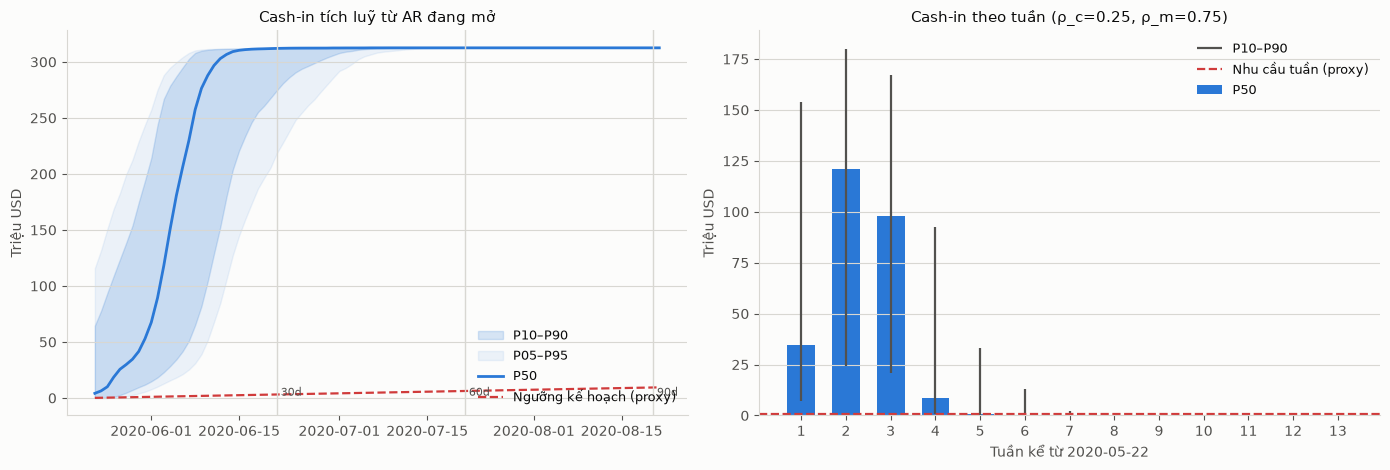

In [15]:
dates = pd.date_range(LIVE_CUTOFF + pd.Timedelta(days=1), periods=HORIZON_DAYS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.fill_between(dates, cum_band["p10"] / 1e6, cum_band["p90"] / 1e6,
                color=C_SERIES[0], alpha=0.18, label="P10–P90")
ax.fill_between(dates, cum_band["p05"] / 1e6, cum_band["p95"] / 1e6,
                color=C_SERIES[0], alpha=0.08, label="P05–P95")
ax.plot(dates, cum_band["p50"] / 1e6, color=C_SERIES[0], lw=2, label="P50")
ax.plot(dates, plan_cum / 1e6, color=C_CRIT, lw=1.6, ls="--", label="Ngưỡng kế hoạch (proxy)")
for h in HORIZONS:
    ax.axvline(dates[h - 1], color=C_GRID, lw=1)
    ax.text(dates[h - 1], 2, f" {h}d", fontsize=8, color=C_INK2)
ax.set_title("Cash-in tích luỹ từ AR đang mở")
ax.set_ylabel("Triệu USD")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="lower right", fontsize=9); ax.grid(axis="x", visible=False)

ax = axes[1]
wk_x = np.arange(1, WEEKS + 1)
ax.bar(wk_x, weekly_band["p50"] / 1e6, color=C_SERIES[0], width=0.62, label="P50")
ax.vlines(wk_x, weekly_band["p10"] / 1e6, weekly_band["p90"] / 1e6,
          color=C_INK2, lw=1.6, label="P10–P90")
ax.axhline(PLAN_WEEKLY / 1e6, color=C_CRIT, lw=1.6, ls="--", label="Nhu cầu tuần (proxy)")
ax.set_xticks(wk_x); ax.set_xlabel(f"Tuần kể từ {LIVE_CUTOFF.date()}")
ax.set_ylabel("Triệu USD"); ax.set_title(f"Cash-in theo tuần (ρ_c={RHO_C}, ρ_m={RHO_M})")
ax.legend(fontsize=9); ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

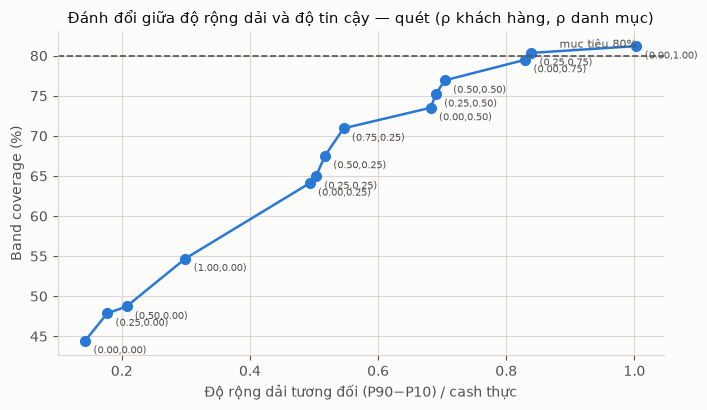

Đọc biểu đồ: giả định độc lập nằm ở góc dưới-trái — dải hẹp nhất và sai nhiều nhất.


In [16]:
# ── Tác động của cấu trúc phụ thuộc lên độ rộng dải ───────────────────────
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(rho_grid.sort_values("rel_band_width")["rel_band_width"],
        rho_grid.sort_values("rel_band_width")["band_coverage"] * 100,
        "o-", color=C_SERIES[0], lw=1.8, ms=7)
ax.axhline(80, color=C_INK2, ls="--", lw=1.2)
ax.text(rho_grid["rel_band_width"].max(), 81, "mục tiêu 80%", ha="right", fontsize=8, color=C_INK2)
for _, r in rho_grid.iterrows():
    ax.annotate(f"({r['rho_cust']:.2f},{r['rho_market']:.2f})",
                (r["rel_band_width"], r["band_coverage"] * 100),
                textcoords="offset points", xytext=(6, -9), fontsize=7, color=C_INK2)
ax.set_xlabel("Độ rộng dải tương đối (P90−P10) / cash thực")
ax.set_ylabel("Band coverage (%)")
ax.set_title("Đánh đổi giữa độ rộng dải và độ tin cậy — quét (ρ khách hàng, ρ danh mục)")
plt.tight_layout(); plt.show()
print("Đọc biểu đồ: giả định độc lập nằm ở góc dưới-trái — dải hẹp nhất và sai nhiều nhất.")

## 7. Xếp hạng rủi ro theo hoá đơn và khách hàng

Rủi ro = **tiền không kịp về trong 30 ngày**: `amount × P(ngày trả > 30)`. Đây là đại lượng
nói được với CFO ("mất bao nhiêu tiền khỏi kỳ này"), không phải một điểm số trừu tượng.

In [17]:
inv_risk = live[["invoice_id", "customer_id", "name_customer", "amount", "due_date",
                 "aging_bucket_at_T", "cal_group", "is_overdue_at_T",
                 "cal_q10", "cal_q50", "cal_q90"]].copy()
inv_risk["expected_days"] = exp_days
for h in HORIZONS:
    inv_risk[f"prob_paid_{h}d"] = paid_prob[h]
inv_risk["expected_cash_30d"] = inv_risk["amount"] * inv_risk["prob_paid_30d"]
inv_risk["risk_amount_30d"] = inv_risk["amount"] * (1 - inv_risk["prob_paid_30d"])
inv_risk["risk_amount_90d"] = inv_risk["amount"] * (1 - inv_risk["prob_paid_90d"])
inv_risk = inv_risk.sort_values("risk_amount_30d", ascending=False).reset_index(drop=True)
inv_risk["risk_rank"] = np.arange(1, len(inv_risk) + 1)
inv_risk["risk_share_cum"] = inv_risk["risk_amount_30d"].cumsum() / inv_risk["risk_amount_30d"].sum()

# Gộp theo customer_id, KHÔNG theo tên: cùng một khách hàng xuất hiện dưới nhiều biến thể
# tên trong dữ liệu gốc, gộp theo tên sẽ chia nhỏ rủi ro tập trung và làm nó biến mất khỏi bảng.
name_by_id = (inv_risk.groupby("customer_id")["name_customer"]
              .agg(lambda s: s.value_counts().index[0]).rename("name_customer"))
cust_risk = (inv_risk.drop(columns=["name_customer"]).groupby("customer_id", dropna=False)
             .agg(invoices=("invoice_id", "count"), open_amount=("amount", "sum"),
                  expected_cash_30d=("expected_cash_30d", "sum"),
                  risk_amount_30d=("risk_amount_30d", "sum"),
                  risk_amount_90d=("risk_amount_90d", "sum"),
                  mean_expected_days=("expected_days", "mean"))
             .join(name_by_id).reset_index().sort_values("risk_amount_30d", ascending=False))
cust_risk["risk_share"] = cust_risk["risk_amount_30d"] / cust_risk["risk_amount_30d"].sum()
cust_risk["risk_share_cum"] = cust_risk["risk_share"].cumsum()

print("Top 10 hoá đơn theo tiền có nguy cơ không về trong 30 ngày")
print(inv_risk.head(10)[["invoice_id", "name_customer", "amount", "aging_bucket_at_T",
                         "cal_q50", "prob_paid_30d", "risk_amount_30d"]].to_string(index=False))
print()
print("Top 10 khách hàng")
print(cust_risk.head(10)[["name_customer", "invoices", "open_amount", "expected_cash_30d",
                          "risk_amount_30d", "risk_share_cum"]].to_string(index=False))
print()
n2 = int(np.ceil(len(inv_risk) * 0.02))
print(f"Tập trung rủi ro: {n2:,} hoá đơn đầu bảng (2%) chiếm "
      f"{inv_risk['risk_share_cum'].iloc[n2-1]:.1%} tổng tiền rủi ro 30 ngày; "
      f"top 10 khách hàng chiếm {cust_risk['risk_share_cum'].iloc[9]:.1%}.")
print()
top_id = cust_risk.iloc[0]["customer_id"]
variants = live.loc[live["customer_id"] == top_id, "name_customer"].nunique()
top_amt = float(cust_risk.iloc[0]["open_amount"])
print(f"Rủi ro tập trung: khách hàng lớn nhất (`customer_id={top_id}`) nắm "
      f"${top_amt:,.0f} = {top_amt/live['amount'].sum():.1%} dư nợ, "
      f"trải trên {int(cust_risk.iloc[0]['invoices']):,} hoá đơn.")
print(f"Khách hàng này xuất hiện dưới {variants} biến thể tên khác nhau trong dữ liệu gốc.")
print("Nếu gộp theo TÊN thay vì theo `customer_id`, rủi ro tập trung này bị chia nhỏ và biến")
print("mất khỏi bảng top — một lỗi trình bày đủ để làm CFO đánh giá sai mức tập trung của sổ AR.")
print("Notebook 06 chạy kịch bản 'khách hàng này không trả' để định lượng mức chịu đựng.")

Top 10 hoá đơn theo tiền có nguy cơ không về trong 30 ngày
 invoice_id     name_customer      amount aging_bucket_at_T  cal_q50  prob_paid_30d  risk_amount_30d
 1930669505      LAKE systems  85,503.600           not_due   38.489          0.028       83,152.251
 1930793545            C&S WH  63,570.970           not_due   31.659          0.141       54,575.678
 1930842496             AM in  53,289.600           not_due   44.189          0.014       52,538.217
 1930645119 SIMPLO associates 653,644.800             31_60   17.779          0.940       39,153.324
 1991840146  WALM corporation  58,838.400              1_30   33.040          0.376       36,732.813
 1930829076       C&S WH corp  24,216.280           not_due   40.472          0.022       23,678.679
 1930831444           SMART &  52,781.030           not_due   29.952          0.596       21,328.814
 1930785539    DELHAIZE trust  35,677.440           not_due   30.049          0.486       18,345.340
 1930603028  KROGE foundation 31

## 8. Lưu artifact

In [18]:
daily_out = pd.DataFrame({
    "date": dates, "day_index": np.arange(1, HORIZON_DAYS + 1),
    "daily_p10": daily_band["p10"], "daily_p50": daily_band["p50"],
    "daily_p90": daily_band["p90"], "daily_mean": daily_band["mean"],
    "cum_p10": cum_band["p10"], "cum_p50": cum_band["p50"],
    "cum_p90": cum_band["p90"], "cum_mean": cum_band["mean"], "plan_cum": plan_cum,
})
daily_out["cum_gap_vs_plan_p10"] = daily_out["cum_p10"] - daily_out["plan_cum"]
daily_out.to_csv(OUT_DAILY, index=False)
print(f"[1] {OUT_DAILY.name}  ({len(daily_out)} ngày)")

weekly_out = pd.DataFrame({
    "week_index": np.arange(1, WEEKS + 1),
    "week_end": [LIVE_CUTOFF + pd.Timedelta(days=7 * w) for w in range(1, WEEKS + 1)],
    "weekly_p10": weekly_band["p10"], "weekly_p50": weekly_band["p50"],
    "weekly_p90": weekly_band["p90"], "weekly_mean": weekly_band["mean"],
    "plan_weekly": PLAN_WEEKLY,
})
weekly_out["gap_vs_plan_p10"] = weekly_out["weekly_p10"] - PLAN_WEEKLY
weekly_out.to_csv(OUT_WEEKLY, index=False)
print(f"[2] {OUT_WEEKLY.name}  ({WEEKS} tuần)")

horizon_summary.to_csv(OUT_HORIZON, index=False)
print(f"[3] {OUT_HORIZON.name}")
inv_risk.to_csv(OUT_INVOICE, index=False)
print(f"[4] {OUT_INVOICE.name}  ({len(inv_risk):,} hoá đơn)")
cust_risk.to_csv(OUT_CUSTOMER, index=False)
print(f"[5] {OUT_CUSTOMER.name}  ({len(cust_risk):,} khách hàng)")

bt_all = pd.concat([
    backtest(snap, ["validation"], BEST_SAMPLER, rho_c=RHO_C, rho_m=RHO_M, label="MC_lgbm"),
    bt_test_mc, bt_test_b1,
], ignore_index=True)
bt_all.to_csv(OUT_BACKTEST, index=False)
print(f"[6] {OUT_BACKTEST.name}  ({len(bt_all)} dòng)")

sampler_selection.to_csv(OUT_SAMPLER, index=False)
rho_grid.to_csv(OUT_RHO, index=False)
shortfall_report.to_csv(OUT_SHORTFALL, index=False)
print(f"[7] {OUT_SAMPLER.name} / {OUT_RHO.name} / {OUT_SHORTFALL.name}")

np.save(PROC / "mc_weekly_sims.npy", weekly_live.astype(np.float32))
np.save(PROC / "mc_daily_sims.npy", daily_live.astype(np.float32))
print("[8] mc_daily_sims.npy / mc_weekly_sims.npy  (notebook 06 dựng stress trên đúng ma trận này)")

[1] mc_daily_cash_forecast.csv  (91 ngày)
[2] mc_weekly_cash_forecast.csv  (13 tuần)
[3] mc_horizon_summary.csv


[4] mc_invoice_risk.csv  (9,681 hoá đơn)
[5] mc_customer_risk.csv  (553 khách hàng)


[6] mc_backtest_weekly.csv  (377 dòng)
[7] mc_sampler_selection.csv / mc_dependence_grid.csv / mc_shortfall_report.csv
[8] mc_daily_sims.npy / mc_weekly_sims.npy  (notebook 06 dựng stress trên đúng ma trận này)


## 9. Sanity check

In [19]:
checks = []


def check(name, cond, detail=""):
    checks.append({"check": name, "pass": bool(cond), "detail": detail})


total_open = amounts_live.sum()
rel_err = abs((daily_live.sum(axis=0) + beyond_live).mean() - total_open) / total_open
check("tổng tiền mô phỏng = tổng dư nợ (không tạo/mất tiền)", rel_err < 1e-9, f"lệch {rel_err:.2e}")
check("dải đơn điệu P10 ≤ P50 ≤ P90 mọi ngày",
      bool((cum_band["p10"] <= cum_band["p50"]).all() and (cum_band["p50"] <= cum_band["p90"]).all()))
check("cash tích luỹ không giảm", bool((np.diff(cum_band["p50"]) >= -1e-6).all()))
check("mọi ngày trả ≥ 1", exp_days.min() >= DAY_FLOOR - 1e-6)
check("prob_paid tăng theo horizon",
      bool((paid_prob[30] <= paid_prob[60] + 1e-9).all() and (paid_prob[60] <= paid_prob[90] + 1e-9).all()))
check("backtest đủ cutoff × tuần",
      len(bt_test_mc) == snap.loc[snap["time_split"] == "test", "cutoff_date"].nunique() * WEEKS)
check("cấu trúc phụ thuộc làm dải rộng hơn giả định độc lập",
      float(rho_grid.loc[(rho_grid.rho_cust == RHO_C) & (rho_grid.rho_market == RHO_M), "rel_band_width"].iloc[0])
      >= float(rho_grid.loc[(rho_grid.rho_cust == 0) & (rho_grid.rho_market == 0), "rel_band_width"].iloc[0]))

checks_df = pd.DataFrame(checks)
print("A. Kiểm tra tính đúng đắn của mô phỏng (bắt buộc pass)")
print(checks_df.to_string(index=False))
print()

# ── B. Phát hiện chuyển sang gate Tầng 9 — đo, không phải điều kiện pass ──
findings = pd.DataFrame([
    {"finding": "CRPS phân phối: LightGBM vs baseline B1",
     "value": f"{mc_crps:.4f} vs {b1d_crps:.4f}",
     "verdict": "model THUA" if mc_crps >= b1d_crps else "model thắng"},
    {"finding": "wMAPE tuần: MC mean vs B1 điểm",
     "value": f"{mc_w:.2%} vs {b1p_w:.2%}",
     "verdict": "model THUA" if mc_w >= b1p_w else "model thắng"},
    {"finding": "Band coverage test (mục tiêu 80%)",
     "value": f"{mc_cov:.1%}", "verdict": "chưa đạt" if mc_cov < 0.75 else "đạt"},
    {"finding": "Forecast 30d vs benchmark lịch sử",
     "value": f"{horizon_summary.loc[0,'share_open_mean']:.1%} vs {bench_30:.1%}",
     "verdict": "LẠC QUAN" if gap30 > 0.05 else "hợp lý"},
])
print("B. Phát hiện chuyển cho gate Tầng 9 (notebook 07) — đây là kết quả đo, không phải lỗi code")
print(findings.to_string(index=False))
print()
if checks_df["pass"].all():
    print("✅ Mô phỏng đúng về mặt kỹ thuật — sang notebook 06 (stress test).")
    print("❗ Nhưng cash gate của Tầng 9 hiện KHÔNG đạt: xem bảng B. Không được ghi 'PASS' trong")
    print("   báo cáo cho đến khi notebook 07 kết luận trên toàn bộ bằng chứng.")
else:
    print("❌ Có check cấu trúc FAIL — dừng lại, không dùng output ở tầng sau.")

A. Kiểm tra tính đúng đắn của mô phỏng (bắt buộc pass)
                                               check  pass        detail
tổng tiền mô phỏng = tổng dư nợ (không tạo/mất tiền)  True lệch 1.91e-16
               dải đơn điệu P10 ≤ P50 ≤ P90 mọi ngày  True              
                            cash tích luỹ không giảm  True              
                                    mọi ngày trả ≥ 1  True              
                         prob_paid tăng theo horizon  True              
                           backtest đủ cutoff × tuần  True              
cấu trúc phụ thuộc làm dải rộng hơn giả định độc lập  True              

B. Phát hiện chuyển cho gate Tầng 9 (notebook 07) — đây là kết quả đo, không phải lỗi code
                                finding            value    verdict
CRPS phân phối: LightGBM vs baseline B1 0.1431 vs 0.1293 model THUA
         wMAPE tuần: MC mean vs B1 điểm 23.21% vs 10.46% model THUA
      Band coverage test (mục tiêu 80%)            53.8%   chưa đ

## Tổng kết Tầng 7

### Kết quả chính
| Câu hỏi của CFO | Trả lời |
|---|---|
| 30 ngày tới thu được bao nhiêu? | dải P10/P50/P90 ở §5b |
| Con số đó có đáng tin không? | §5c — so với benchmark lịch sử, forecast đang **lạc quan ~12 điểm %** |
| Xấu nhất thì thiếu tiền từ ngày nào? | §5d (gắn với ngưỡng proxy D30) |
| Ai làm hỏng dòng tiền? | §7 — xếp theo `amount × P(chưa trả trong 30 ngày)` |
| Model có thắng baseline trên dòng tiền không? | §4d — **chưa**, thua cả trên wMAPE lẫn CRPS |

### Bốn phát hiện phải đưa vào báo cáo

1. **Giả định độc lập làm dải cash-in vô dụng** (§4b): band coverage 44%. Sau khi hiệu chỉnh
   cấu trúc phụ thuộc trên validation, dải rộng ra nhiều lần và coverage lên ~80% (validation).
   Đây là loại lỗi prototype thường không phát hiện, vì dải hẹp **trông** như dự báo chính xác.

2. **Sai lệch timing mức model** (§4b): tuần 1 luôn bị dự báo thiếu (100% số cutoff có tiền
   thực nằm trên P90), tuần 3–9 bị dự báo thừa. Cấu trúc phụ thuộc không sửa được phần này —
   nó là sai lệch của chính model.

3. **Model vẫn thua baseline trên dòng tiền** (§4d). Đây là kết quả trung thực và cần được
   trình bày chủ động:

   | Dự báo | wMAPE tuần | CRPS chuẩn hoá |
   |---|---:|---:|
   | B1 điểm | ~10% | — |
   | LGBM Q50 điểm | ~18% | — |
   | B1 + bootstrap (phân phối) | ~20% | ~0,129 |
   | LGBM + CQR + MC (phân phối) | ~23% | ~0,143 |

   Đọc đúng: baseline B1 là điểm dự báo **kém sắc** hơn (MAE ngày tệ hơn 12%) nhưng phân phối
   residual của nó **rộng và trung thực hơn**, nên khi cộng thành dòng tiền tuần nó thắng.
   Nói cách khác, LightGBM đang **sắc nét mà chưa hiệu chỉnh đúng ở mức tổng** — sharpness
   không bù được calibration. Đây chính xác là điều rule 3 của Tầng 9 cảnh báo, và nó đến từ
   cùng một gốc với phát hiện 4.

4. **Forecast nhanh hơn cả benchmark lịch sử** (§5c): +11,9 điểm % tại mốc 30 ngày, trong khi
   benchmark đó vốn đã lạc quan (snapshot chỉ chứa hoá đơn cuối cùng được trả). Đây là hệ quả
   trực tiếp của P0-1. **Notebook 08 xử lý gốc vấn đề bằng survival có censoring.**

### Cách trình bày trước hội đồng
Không giấu phát hiện 3. Câu chuyện đúng là: *"Chúng tôi đã đo cash metric theo đúng cách plan
yêu cầu, phát hiện model chưa thắng baseline ở mức dòng tiền, truy được nguyên nhân về lệch
phân bố train/inference, và đang xử lý bằng survival."* Đó là một kết quả mạnh hơn nhiều so
với một con số PASS không kiểm chứng được.

### Giả định phải khai báo
1. Marginal của từng hoá đơn lấy từ LightGBM + CQR; copula Gaussian chỉ mô tả liên kết (D31).
2. Đuôi phải dạng mũ với `s=(q₉₀−q₅₀)/2` là lựa chọn thiết kế, không phải kết quả fit (D24).
3. Ngưỡng kế hoạch là proxy từ lịch sử thu, không phải kế hoạch chi thật (D30).
4. Backtest chạy trên pool snapshot (93% chưa đến hạn), khác pool đang mở (94,8% quá hạn).